In [1]:
import pandas as pd
import numpy as np

## Task 1: Data Binning

In [12]:

df_t1 = pd.DataFrame({
    "ID": [1, 2, 3, 4, 5, 6, 7, 8],
    "Age": [12, 25, 47, 33, 56, 80, 21, 39]
})

bins = [0, 12, 19, 35, 59, 100]
labels = ["Child", "Teen", "Young Adult", "Middle Aged", "Senior"]

df_t1["Age_Group"] = pd.cut(df_t1["Age"], bins=bins, labels=labels)
print(df_t1)

print("\nFrequency of each age group:")
print(df_t1["Age_Group"].value_counts())

   ID  Age    Age_Group
0   1   12        Child
1   2   25  Young Adult
2   3   47  Middle Aged
3   4   33  Young Adult
4   5   56  Middle Aged
5   6   80       Senior
6   7   21  Young Adult
7   8   39  Middle Aged

Frequency of each age group:
Age_Group
Young Adult    3
Middle Aged    3
Child          1
Senior         1
Teen           0
Name: count, dtype: int64


## Task 2: Standardization Using Z-Score

In [8]:

df_t2 = pd.DataFrame({
    "ID": [1, 2, 3, 4, 5, 6],
    "Exam_Score": [65, 70, 82, 90, 55, 73]
})

mean_score = df_t2["Exam_Score"].mean()
std_score = df_t2["Exam_Score"].std()   # pandas uses n-1 (sample std)

print("Mean:", round(mean_score, 4))
print("Standard Deviation:", round(std_score, 4))

df_t2["Z_Score"] = (df_t2["Exam_Score"] - mean_score) / std_score
print("\nStandardized values:")
print(df_t2.round(4))

Mean: 72.5
Standard Deviation: 12.3734

Standardized values:
   ID  Exam_Score  Z_Score
0   1          65  -0.6061
1   2          70  -0.2020
2   3          82   0.7678
3   4          90   1.4143
4   5          55  -1.4143
5   6          73   0.0404


## Task 3: Categorical Data Encoding

In [13]:

from sklearn.preprocessing import LabelEncoder, OneHotEncoder

df_t3 = pd.DataFrame({
    "ID": [1, 2, 3, 4, 5, 6],
    "Color": ["Red", "Blue", "Green", "Red", "Green", "Blue"]
})

# Label Encoding
le = LabelEncoder()
df_label = df_t3.copy()
df_label["Color_Label"] = le.fit_transform(df_label["Color"])
print("Label Encoded:")
print(df_label)
print("Mapping:", dict(zip(le.classes_, le.transform(le.classes_))))



Label Encoded:
   ID  Color  Color_Label
0   1    Red            2
1   2   Blue            0
2   3  Green            1
3   4    Red            2
4   5  Green            1
5   6   Blue            0
Mapping: {'Blue': np.int64(0), 'Green': np.int64(1), 'Red': np.int64(2)}


In [14]:
# One-Hot Encoding
ohe = OneHotEncoder(sparse_output=False, dtype=int)
encoded = ohe.fit_transform(df_t3[["Color"]])
df_onehot = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(["Color"]))
df_onehot.insert(0, "ID", df_t3["ID"])
print("\nOne-Hot Encoded:")
print(df_onehot)


One-Hot Encoded:
   ID  Color_Blue  Color_Green  Color_Red
0   1           0            0          1
1   2           1            0          0
2   3           0            1          0
3   4           0            0          1
4   5           0            1          0
5   6           1            0          0


## Task 4: Handling Missing Values

In [18]:

df_emp = pd.DataFrame({
    "ID": [1, 2, 3, 4, 5],
    "Name": ["Alex", "Ben", "Chris", "Dana", "Eva"],
    "Age": [25, np.nan, 30, 28, 35],
    "Gender": ["Male", "Male", np.nan, "Female", "Female"],
    "Salary": [50000, 60000, 70000, np.nan, 80000]
})
print("Original Dataset:")
print(df_emp)


print("\nMissing values in each column:")
print(df_emp.isnull().sum())




Original Dataset:
   ID   Name   Age  Gender   Salary
0   1   Alex  25.0    Male  50000.0
1   2    Ben   NaN    Male  60000.0
2   3  Chris  30.0     NaN  70000.0
3   4   Dana  28.0  Female      NaN
4   5    Eva  35.0  Female  80000.0

Missing values in each column:
ID        0
Name      0
Age       1
Gender    1
Salary    1
dtype: int64


In [19]:
print("\nAfter dropna() (drop rows with any missing value):")
print(df_emp.dropna())

print("\nAfter dropna(axis=1) (drop columns with any missing value):")
print(df_emp.dropna(axis=1))


After dropna() (drop rows with any missing value):
   ID  Name   Age  Gender   Salary
0   1  Alex  25.0    Male  50000.0
4   5   Eva  35.0  Female  80000.0

After dropna(axis=1) (drop columns with any missing value):
   ID   Name
0   1   Alex
1   2    Ben
2   3  Chris
3   4   Dana
4   5    Eva


In [21]:

df_clean = df_emp.copy()
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Salary"] = df_clean["Salary"].fillna(df_clean["Salary"].median())

df_clean["Gender"] = df_clean["Gender"].fillna(df_clean["Gender"].mode()[0])


print("\nCleaned Dataset:")
print(df_clean)
print("\nTotal missing values after cleaning:", df_clean.isnull().sum().sum())


Cleaned Dataset:
   ID   Name   Age  Gender   Salary
0   1   Alex  25.0    Male  50000.0
1   2    Ben  29.0    Male  60000.0
2   3  Chris  30.0  Female  70000.0
3   4   Dana  28.0  Female  65000.0
4   5    Eva  35.0  Female  80000.0

Total missing values after cleaning: 0


## Task 5: Data Visualization Using Seaborn

In [22]:

import seaborn as sns
import matplotlib.pyplot as plt

df_staff = pd.DataFrame({
    "ID": [1, 2, 3, 4, 5, 6, 7, 8],
    "Gender": ["Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female"],
    "Age": [25, 30, 22, 35, 40, 28, 32, 45],
    "Salary": [50000, 60000, 45000, 70000, 80000, 55000, 62000, 90000],
    "Experience": [2, 5, 1, 8, 10, 3, 6, 12]
})
print(df_staff)
print("\nAverage Salary by Gender:")
print(df_staff.groupby("Gender")["Salary"].mean())

   ID  Gender  Age  Salary  Experience
0   1    Male   25   50000           2
1   2  Female   30   60000           5
2   3    Male   22   45000           1
3   4  Female   35   70000           8
4   5    Male   40   80000          10
5   6  Female   28   55000           3
6   7    Male   32   62000           6
7   8  Female   45   90000          12

Average Salary by Gender:
Gender
Female    68750.0
Male      59250.0
Name: Salary, dtype: float64


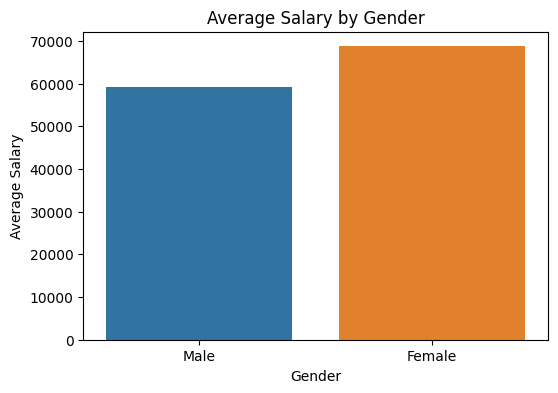

In [23]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df_staff, x="Gender", y="Salary", hue="Gender", errorbar=None, legend=False)
plt.title("Average Salary by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Salary")
plt.show()

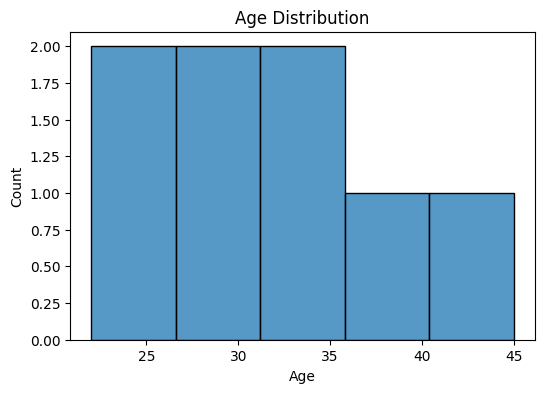

In [24]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df_staff, x="Age", bins=5)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

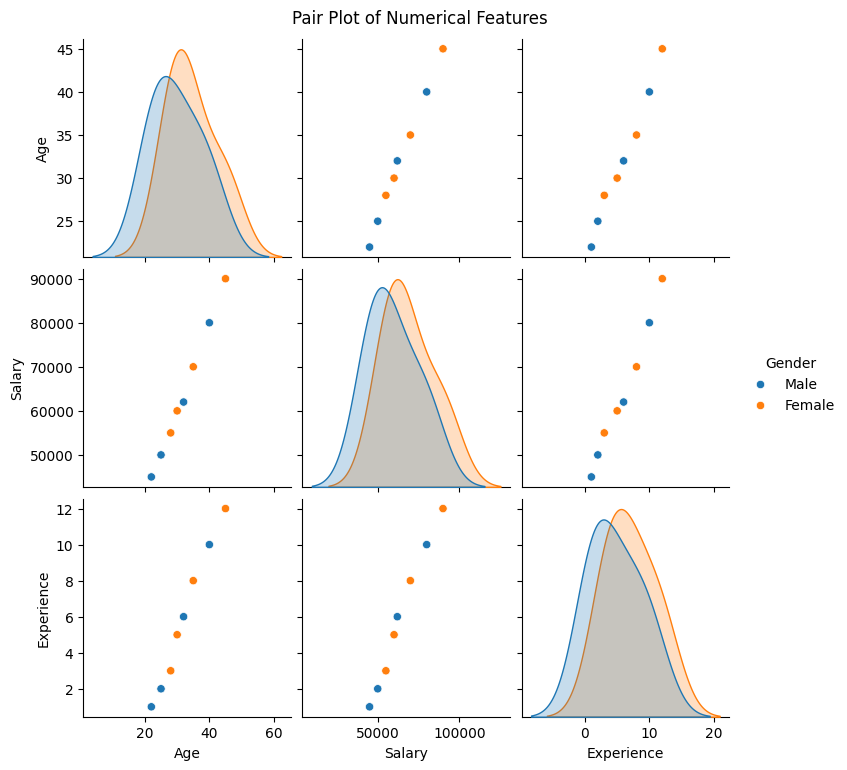

In [25]:
g = sns.pairplot(df_staff[["Age", "Salary", "Experience", "Gender"]], hue="Gender")
g.figure.suptitle("Pair Plot of Numerical Features", y=1.02)
plt.show()

## Task 6: Dimensionality Reduction Using PCA

In [27]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_heart = pd.DataFrame({
    "ID": list(range(1, 16)),
    "Age": [29, 34, 37, 41, 45, 31, 39, 43, 48, 50, 52, 55, 58, 47, 60],
    "RestingBP": [120, 118, 125, 130, 128, 115, 122, 132, 135, 140, 138, 145, 150, 142, 155],
    "Cholesterol": [180, 190, 205, 210, 220, 175, 198, 215, 235, 245, 230, 250, 265, 240, 280],
    "MaxHR": [175, 168, 165, 160, 155, 180, 170, 158, 150, 145, 148, 140, 138, 152, 130],
    "Target": [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
})

features = ["Age", "RestingBP", "Cholesterol", "MaxHR"]
X = df_heart[features]          # ID and Target are NOT included
print("Input features:", list(X.columns))

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
print("\nExplained variance ratio:", explained.round(4))
print("Cumulative explained variance:", cumulative.round(4))

n_components_95 = np.argmax(cumulative >= 0.95) + 1
print("\nComponents needed for at least 95% variance:", n_components_95)

Input features: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']

Explained variance ratio: [0.9813 0.0112 0.005  0.0025]
Cumulative explained variance: [0.9813 0.9925 0.9975 1.    ]

Components needed for at least 95% variance: 1


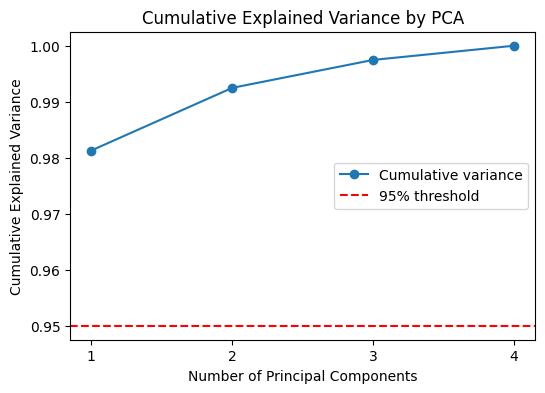

In [28]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o", label="Cumulative variance")
plt.axhline(y=0.95, color="red", linestyle="--", label="95% threshold")
plt.title("Cumulative Explained Variance by PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative) + 1))
plt.legend()
plt.show()

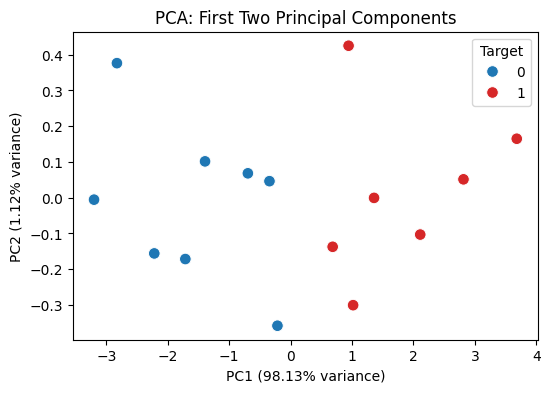

In [29]:
df_pca = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Target": df_heart["Target"]})

plt.figure(figsize=(6, 4))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Target", palette=["tab:blue", "tab:red"], s=70)
plt.title("PCA: First Two Principal Components")
plt.xlabel(f"PC1 ({explained[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({explained[1]*100:.2f}% variance)")
plt.legend(title="Target")
plt.show()

## Task 7: Dimensionality Reduction Using t-SNE

        TSNE1       TSNE2  Target
0   63.450001 -123.269997       0
1   53.590000 -102.650002       0
2   40.639999  -77.650002       0
3   27.440001  -54.669998       0
4    9.280000  -35.009998       0
5   80.199997 -110.570000       0
6   60.669998  -81.620003       0
7   29.709999  -34.369999       0
8   -8.580000    8.910000       1
9  -22.350000   30.290001       1
10 -28.240000    5.030000       1
11 -29.299999   54.310001       1
12 -40.790001   72.389999       1
13 -42.810001   21.150000       1
14 -24.440001   84.940002       1





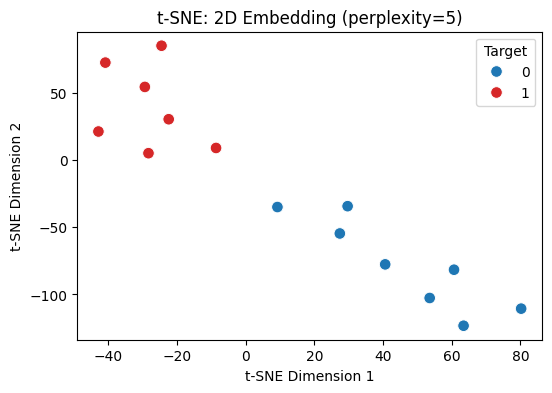

In [31]:

from sklearn.manifold import TSNE

# Same standardized features from Task 6 (ID and Target excluded)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

df_tsne = pd.DataFrame({"TSNE1": X_tsne[:, 0], "TSNE2": X_tsne[:, 1], "Target": df_heart["Target"]})
print(df_tsne.round(2))

plt.figure(figsize=(6, 4))
sns.scatterplot(data=df_tsne, x="TSNE1", y="TSNE2", hue="Target", palette=["tab:blue", "tab:red"], s=70)
plt.title("t-SNE: 2D Embedding (perplexity=5)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Target")
print("\n\n")
plt.show()